# Assignment 4: Exploratory Data Analysis with pandas

**Learning outcomes**
- Load and manipulate data with pandas.
- Handle missing values and outliers.
- Summarise data with descriptive statistics.
- Create basic visualisations (histograms, box plots, bar plots).
- Derive and communicate insights.
- Automate EDA with a profiling library (Part B) and produce `eda_report.html`.

**Dataset note.** The assignment suggests the Netflix Movies and TV Shows dataset (Kaggle). That file could not be downloaded in the environment used to build this notebook, so this notebook uses the **Wine dataset** from scikit-learn. It is a real dataset from the UCI Machine Learning Repository: 178 Italian wines with 13 chemical measurements and a cultivar label. To use Netflix instead, download `netflix_titles.csv` from Kaggle, place it beside this notebook, and set `DATA_PATH` in Section 1 (the later cells use generic column detection, but the column-specific sections will need the Netflix column names).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 30)


## Part A: Exploratory data analysis

### 1. Load the data

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame.rename(columns={"target": "cultivar"})
df["cultivar"] = df["cultivar"].map(dict(enumerate(wine.target_names)))

print("Shape (rows, columns):", df.shape)
display(df.head())


Shape (rows, columns): (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


### 2. Inspect structure and data types

In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  culti

### 3. Missing values

The original dataset has no missing values. To practise the handling methods, we create a copy with 5% of values removed at random, then treat them. The original data is kept unchanged.

In [4]:
print("Missing values in the original data:", df.isna().sum().sum())

rng = np.random.default_rng(0)
df_missing = df.copy()
features = df.select_dtypes("number").columns
mask = rng.random(df_missing[features].shape) < 0.05
df_missing[features] = df_missing[features].mask(mask)

print("Missing values after simulation:", df_missing.isna().sum().sum())
print((df_missing.isna().mean()[features] * 100).round(1).sort_values(ascending=False).head(5))

# Handling: fill numeric gaps with the column median (robust to outliers)
df_clean = df_missing.copy()
df_clean[features] = df_clean[features].fillna(df_clean[features].median())
print("Missing values after handling:", df_clean.isna().sum().sum())


Missing values in the original data: 0
Missing values after simulation: 128
malic_acid              8.4
magnesium               7.3
ash                     7.3
nonflavanoid_phenols    6.7
alcalinity_of_ash       6.2
dtype: float64
Missing values after handling: 0


### 4. Outliers with the IQR rule

A value is flagged as an outlier if it lies below Q1 − 1.5·IQR or above Q3 + 1.5·IQR. Flagging is not the same as deleting: an unusual value may be genuine.

In [5]:
def iqr_outliers(frame, cols):
    out = {}
    for c in cols:
        q1, q3 = frame[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        out[c] = int(((frame[c] < lo) | (frame[c] > hi)).sum())
    return pd.Series(out).sort_values(ascending=False)

outlier_counts = iqr_outliers(df_clean, features)
display(outlier_counts.to_frame("outliers"))


,outliers
malic_acid,6
alcalinity_of_ash,6
ash,6
color_intensity,5
proanthocyanins,5
magnesium,4
hue,1
proline,1
alcohol,0
nonflavanoid_phenols,0


Next we cap the extreme values (winsorise) at the IQR fences, so the analysis is less affected by them while keeping every row.

In [6]:
df_capped = df_clean.copy()
for c in features:
    q1, q3 = df_capped[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    df_capped[c] = df_capped[c].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

print("Outliers remaining after capping:", iqr_outliers(df_capped, features).sum())


Outliers remaining after capping: 0


### 5. Descriptive statistics

In [7]:
desc = df_capped[["alcohol", "malic_acid", "proline", "color_intensity", "flavanoids"]].describe().T
desc["skew"] = df_capped[desc.index].skew()
display(desc.round(2))


,count,mean,std,min,25%,50%,75%,max,skew
alcohol,178.0,13.00,0.81,11.03,12.37,13.05,13.66,14.83,-0.04
malic_acid,178.0,2.26,1.03,0.74,1.61,1.83,2.88,4.77,1.00
proline,178.0,750.31,300.79,278.00,516.25,679.00,961.75,1630.00,0.80
color_intensity,178.0,5.03,2.16,1.28,3.30,4.70,6.12,10.36,0.73
flavanoids,178.0,2.06,0.98,0.34,1.26,2.17,2.84,5.08,-0.01


### 6. Histograms: distribution of key measurements

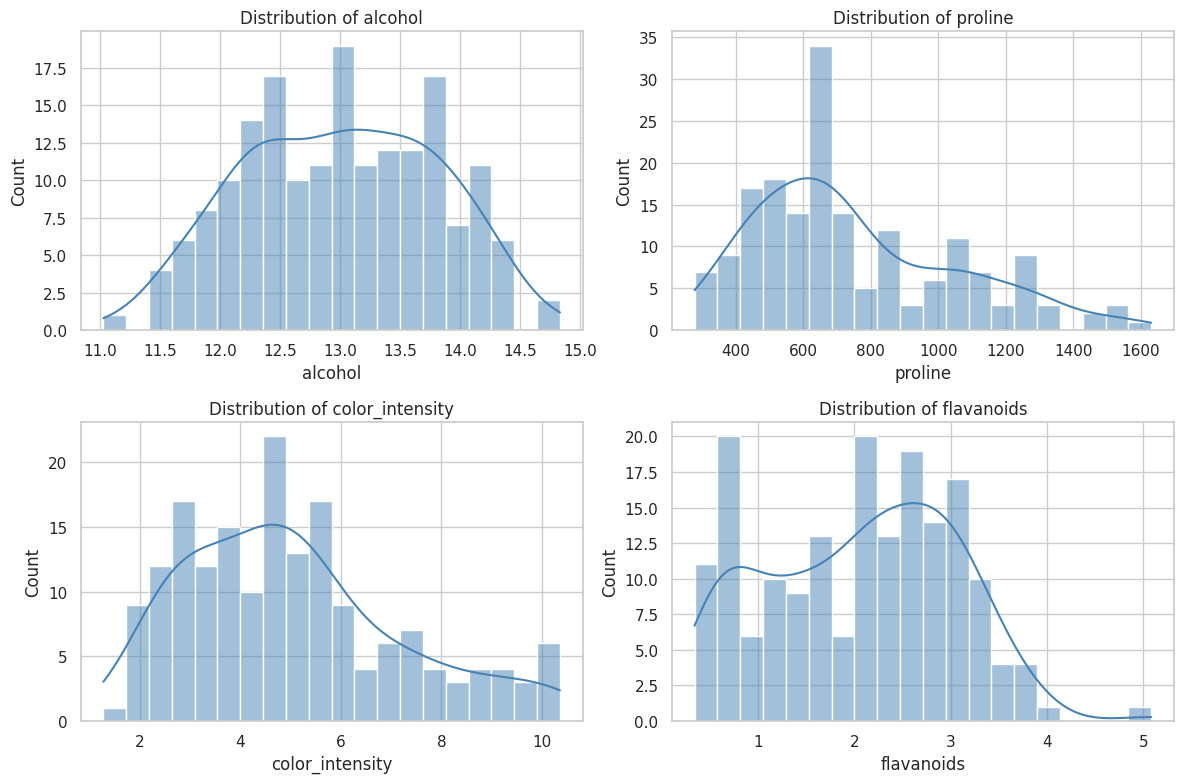

In [8]:
cols = ["alcohol", "proline", "color_intensity", "flavanoids"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(df_capped[c], bins=20, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {c}")
plt.tight_layout()
plt.show()


### 7. Box plots: comparing cultivars

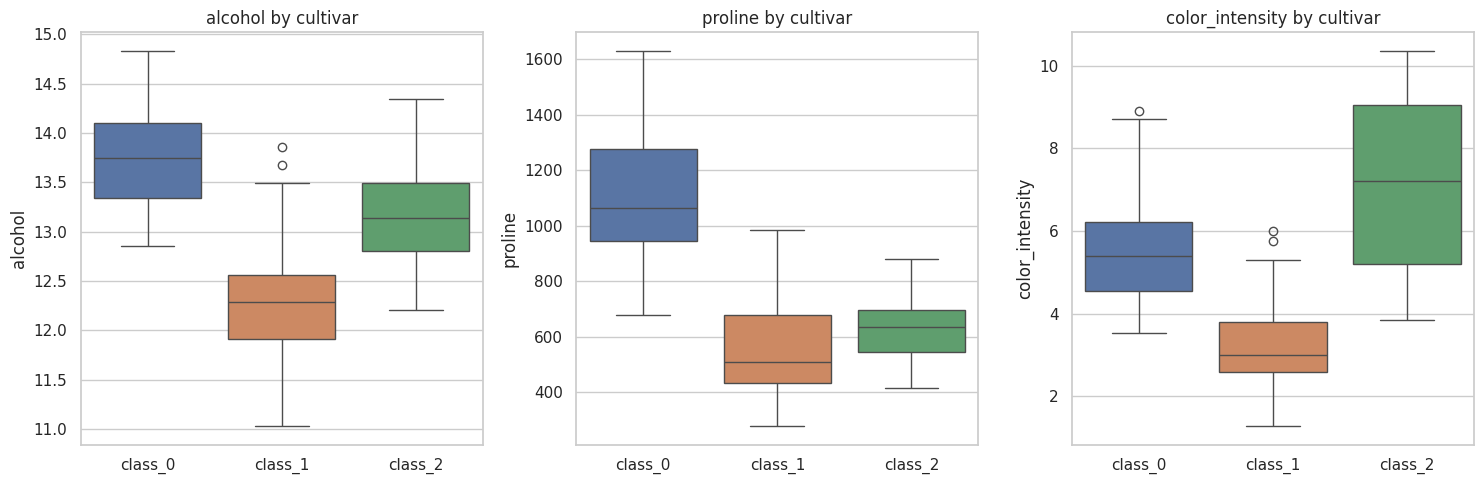

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, c in zip(axes, ["alcohol", "proline", "color_intensity"]):
    sns.boxplot(data=df_capped, x="cultivar", y=c, hue="cultivar", legend=False, ax=ax)
    ax.set_title(f"{c} by cultivar")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()


### 8. Bar plot: number of samples per cultivar

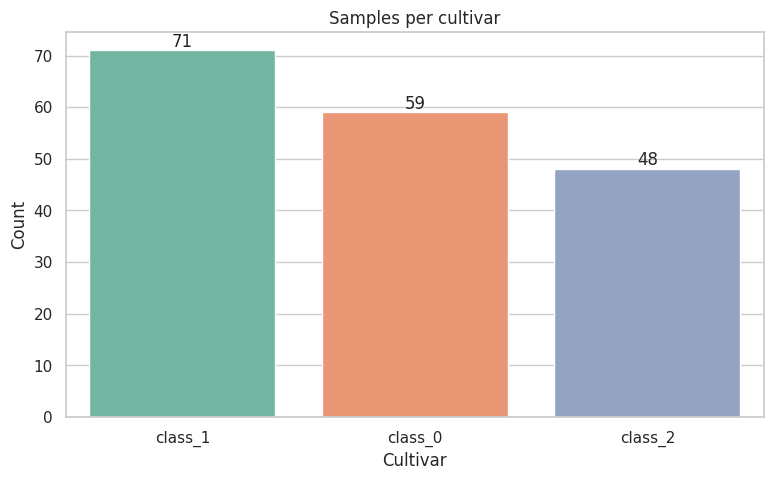

In [10]:
counts = df_capped["cultivar"].value_counts()
fig, ax = plt.subplots()
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, legend=False, ax=ax, palette="Set2")
ax.set_title("Samples per cultivar")
ax.set_xlabel("Cultivar")
ax.set_ylabel("Count")
for c in ax.containers:
    ax.bar_label(c)
plt.show()


### 9. Relationships between variables

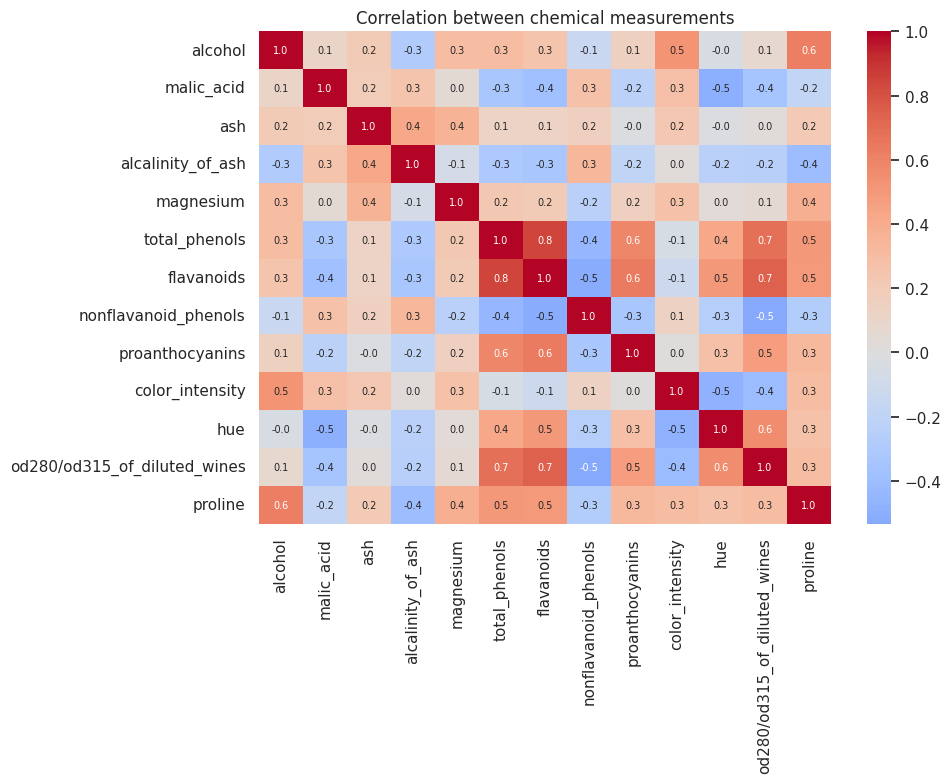

Strongest correlations:
total_phenols  flavanoids                      0.85
flavanoids     od280/od315_of_diluted_wines    0.75
total_phenols  od280/od315_of_diluted_wines    0.68
flavanoids     proanthocyanins                 0.63
alcohol        proline                         0.62
dtype: float64


In [11]:
corr = df_capped[features].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation between chemical measurements")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Strongest correlations:")
print(pairs.abs().sort_values(ascending=False).head(5).round(2))


### 10. Insights

Run the cells above and write your own findings here. Typical points to address:
- Which variables are most skewed, and what that means for choosing mean or median.
- Which measurements separate the three cultivars most clearly (the box plots help here).
- Which pairs of variables are strongly correlated, and whether that suggests redundant features.
- How many outliers were found, and whether capping changes the picture.

## Part B: Automated profiling with ydata-profiling

The profiling library produces a full HTML report covering types, missing values, distributions, correlations and warnings. The next cell creates `eda_report.html`. Install it once with `pip install ydata-profiling` if it is not already available.

In [12]:
try:
    from ydata_profiling import ProfileReport
    profile = ProfileReport(df_missing, title="Wine Dataset EDA", explorative=True, minimal=False)
    profile.to_file("eda_report.html")
    print("Saved eda_report.html")
except ImportError:
    print("ydata-profiling is not installed. Run: pip install ydata-profiling, then rerun this cell.")


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/tmp/ipykernel_537/3584593566.py:2: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Summarize dataset:   0%|          | 0/19 [00:00<?, ?it/s, Describe variable: alcohol]

Summarize dataset:   0%|          | 0/19 [00:00<?, ?it/s, Describe variable: malic_acid]

...

Render HTML: 100%|██████████| 1/1 [00:00<00:00,  1.86it/s]

Render HTML: 100%|██████████| 1/1 [00:00<00:00,  1.86it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 38.96it/s]

Saved eda_report.html


### Actionable insights from the profiling report

Open `eda_report.html` and note:
1. **Warnings** on high correlation: correlated features can be reduced or combined before modelling.
2. **Skewed variables**: consider a log transform or a robust model for these.
3. **Missing-value pattern**: the profile should show the simulated gaps. In real data, check whether gaps are random or systematic before choosing a fill method.
4. **Feature recommendations** for model training: keep features that separate the cultivars clearly, and review those flagged as redundant.

**Credit-risk example (from the brief):** the same steps apply to loan applicant data. Look for missing income or employment fields, outliers in loan amount, and features strongly related to default, then recommend which ones to include in a model.